PROJECT ON TELCO CUSTOMER CHURN PREDICTION

In [41]:
from pathlib import Path
# Directory where the notebook is running
NOTEBOOK_DIR = Path.cwd()
# Assuming the Project-Telco/notebooks/eda.ipynb
PROJECT_ROOT = NOTEBOOK_DIR.parent
DATA_RAW = PROJECT_ROOT/"data"/"raw"
DATA_PROCESSED = PROJECT_ROOT/"data"/"processed"
# Path to the raw csv
data_raw_path = DATA_RAW/"Telco-Customer-Churn.csv"


In [42]:
# importing required libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

DATASET:

This is a customer churn dataset from IBM, designed to analyse why customers leave a company and help develop targeted retention strategies.
Each row represents an individual customer, tracked across four core categories: their churn status (whether they left or stayed), the services they subscribe to (such as phone, internet, multiple lines, online security, backup, device protection, tech support, and streaming), their account details (including tenure, contract type, payment method, paperless billing, monthly charges, and total charges), and their demographic background (gender, age group, partner status, and dependents).

In [43]:
# Loading data
df_raw = pd.read_csv(data_raw_path)
# returns a tuple containing the number of (rows, columns)
df_raw.shape 

(7043, 21)

In [44]:
# returns first 5 rows
df_raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [45]:
# structural summary of the dataframe
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [46]:
# Statistical summary of the dataframe
df_raw.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


Based on  describe(include="all")  and initial exploratory analysis, most categorical variables contain two, three, or four unique categories. 
For variables with exactly two categories, convert the values into binary format using  0  and  1.
For variables with three or four categories, use one-hot encoding to create separate binary columns for each category.
This preprocessing converts categorical data into a numerical format that machine-learning algorithms can use effectively, without implying an artificial order between categories.

Make a copy of df_raw file so that the original file remains safe and untouched.

In [47]:
df = df_raw.copy()
# displays last 3 rows
df.tail(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [48]:
# Checking for class imbalance
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

We have a class imbalance problem

CLEANING

Dropping the customerID because it is irrelevant for the churn prediction.

In [49]:
df = df.drop('customerID', axis =1)

In [50]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [51]:
df["InternetService"].unique()

<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

VISUALISING THE DATA

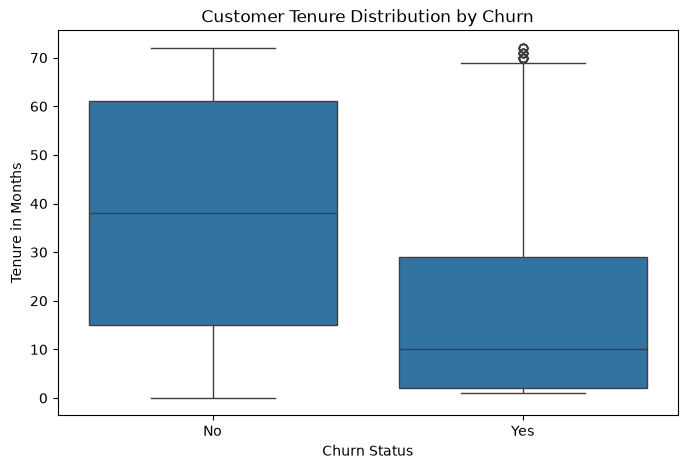

In [52]:
# VISUALISATION 1: Continuous Distribution Check (Tenure vs Churn)
plt.figure(figsize=(8,5))
sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure in Months")
plt.show()

It shows that cx with lower tenure is most likely to leave.


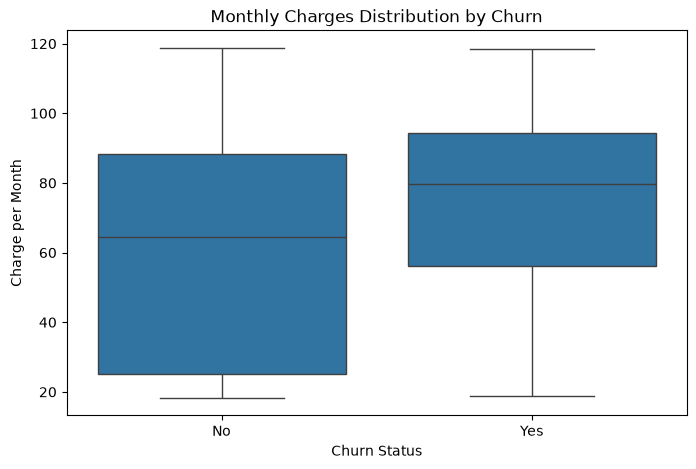

In [53]:
# VISUALISATION 2: Continuous Distribution Check (Monthly Charges vs Churn)
plt.figure(figsize=(8,5))
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Churn Status")
plt.ylabel("Charge per Month")
plt.show()

It shows that cx with high monthly charges are most likely to leave.

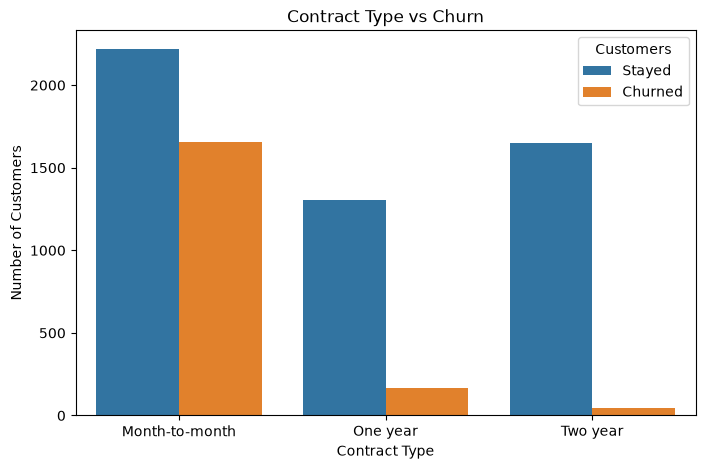

In [54]:
# VISUALISATION 3: Contract type vs Churn
plt.figure(figsize=(8,5))
sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Contract Type vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.legend(title="Customers", labels=["Stayed", "Churned"])
plt.show()


It shows that cx with long term contracts are less likely to leave.

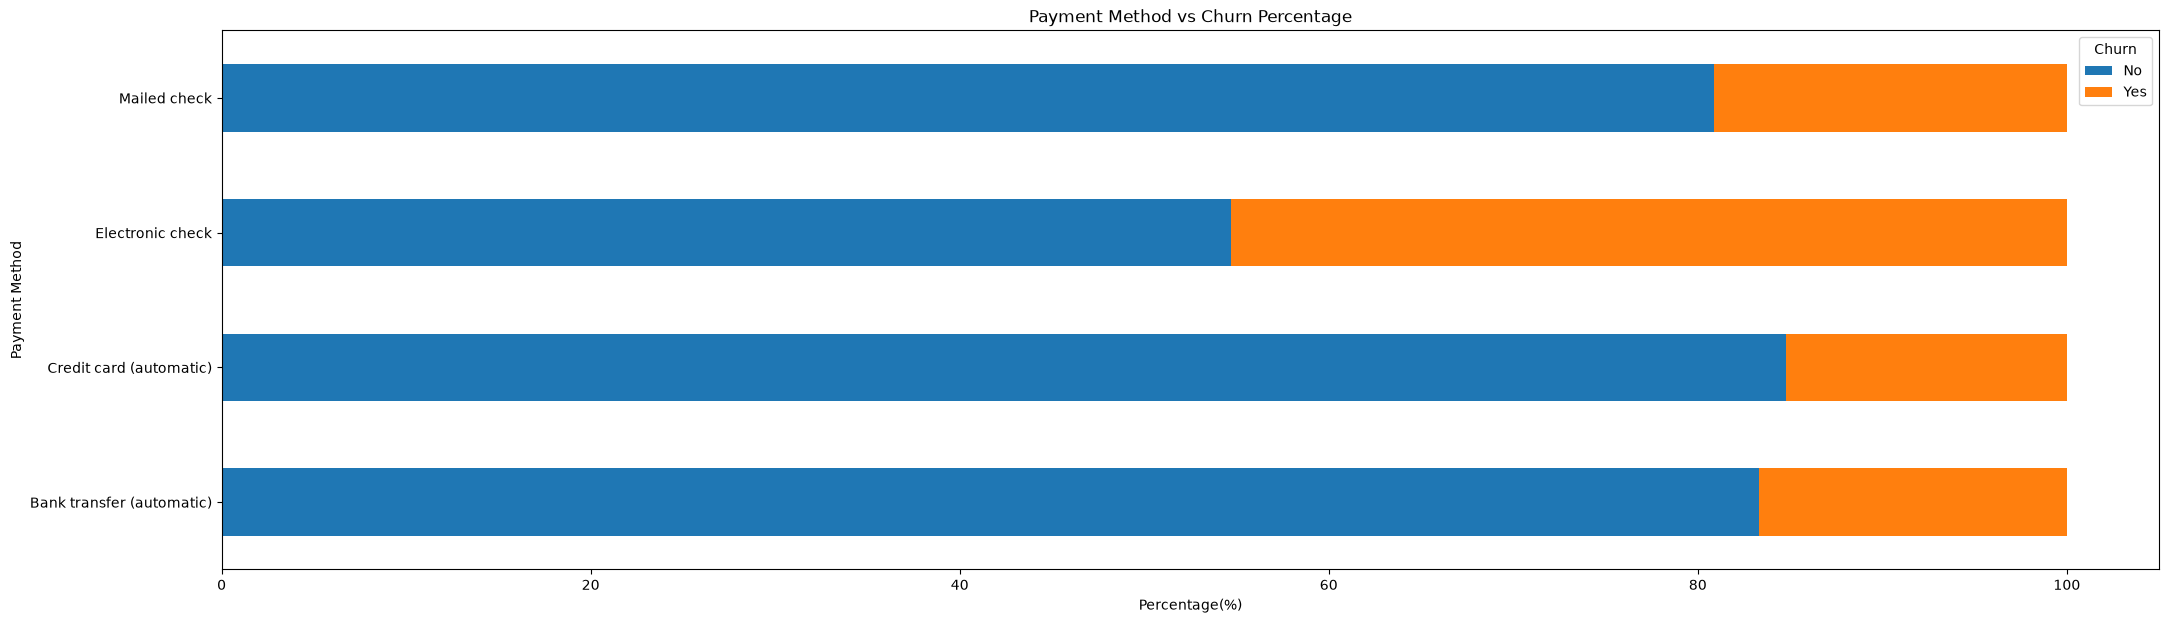

In [55]:
# VISUALISATION 4: Normalised cross-tabulation of Payment Method vs Churn
payment_churn = pd.crosstab(df["PaymentMethod"], df["Churn"], normalize='index') * 100
payment_churn.plot(kind="barh", stacked=True, figsize=(25,7))
plt.title("Payment Method vs Churn Percentage")
plt.xlabel("Percentage(%)")
plt.ylabel("Payment Method")
plt.show()

It shows that cx paying using an electronic check are more likely to leave.

BINARY ENCODING

Categorical columns with exactly 2 unique values we use pandas replace

In [56]:
#  categorical columns with 2 values
binary_columns = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']

# Replace the values with 0 or 1
df[binary_columns] = df[binary_columns].replace ({'Yes': 1, 'No': 0, 'Female': 1, 'Male': 0})

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,1,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,0,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.5,0
2,0,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,0,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,1,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


ONE-HOT ENCODING

For Categorical Columns with more than 2 unique values use One-Hot Encoding

In [57]:
multi_category_columns = [
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaymentMethod'
]

# one-hot encode
df = pd.get_dummies(df, columns=multi_category_columns, drop_first=True)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1,0,1,0,1,0,1,29.85,29.85,0,...,False,False,False,False,False,False,False,False,True,False
1,0,0,0,0,34,1,0,56.95,1889.5,0,...,False,False,False,False,False,True,False,False,False,True
2,0,0,0,0,2,1,1,53.85,108.15,1,...,False,False,False,False,False,False,False,False,False,True
3,0,0,0,0,45,0,0,42.30,1840.75,0,...,True,False,False,False,False,True,False,False,False,False
4,1,0,0,0,2,1,1,70.70,151.65,1,...,False,False,False,False,False,False,False,False,True,False


In [58]:
# check the data types of all columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7043 non-null   object 
 1   SeniorCitizen                          7043 non-null   int64  
 2   Partner                                7043 non-null   object 
 3   Dependents                             7043 non-null   object 
 4   tenure                                 7043 non-null   int64  
 5   PhoneService                           7043 non-null   object 
 6   PaperlessBilling                       7043 non-null   object 
 7   MonthlyCharges                         7043 non-null   float64
 8   TotalCharges                           7043 non-null   str    
 9   Churn                                  7043 non-null   object 
 10  MultipleLines_No phone service         7043 non-null   bool   
 11  MultipleLines_Y

We want all the values in numeric format i.e, int or float  so that the ML models can work on it.

Total Charges are in string datatype format and we need to change it to numeric type.

Some Columns contains boolean datatype  and we need to change those to numeric as well.

In [59]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'Churn', 'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No internet service', 'StreamingMovies_Yes',
       'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='str')

In [60]:
# string to numeric, errors =coerce to prevent crashing and null to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')


In [61]:
# Boolean columns
boolean_columns = df.select_dtypes(include='bool').columns
# convert boolean to integers
df[boolean_columns] = df[boolean_columns].astype(int)

In [62]:
# Columns with object dtype
object_columns = df.select_dtypes('object').columns
# Convert object to numeric
df[object_columns] = df[object_columns].apply(pd.to_numeric, errors='coerce')

In [63]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7043 non-null   int64  
 1   SeniorCitizen                          7043 non-null   int64  
 2   Partner                                7043 non-null   int64  
 3   Dependents                             7043 non-null   int64  
 4   tenure                                 7043 non-null   int64  
 5   PhoneService                           7043 non-null   int64  
 6   PaperlessBilling                       7043 non-null   int64  
 7   MonthlyCharges                         7043 non-null   float64
 8   TotalCharges                           7032 non-null   float64
 9   Churn                                  7043 non-null   int64  
 10  MultipleLines_No phone service         7043 non-null   int64  
 11  MultipleLines_Y

CHECK & HANDLE MISSING VALUES, DUPLICATE ROWS

In [64]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
gender                                    0
SeniorCitizen                             0
Partner                                   0
Dependents                                0
tenure                                    0
PhoneService                              0
PaperlessBilling                          0
MonthlyCharges                            0
TotalCharges                             11
Churn                                     0
MultipleLines_No phone service            0
MultipleLines_Yes                         0
InternetService_Fiber optic               0
InternetService_No                        0
OnlineSecurity_No internet service        0
OnlineSecurity_Yes                        0
OnlineBackup_No internet service          0
OnlineBackup_Yes                          0
DeviceProtection_No internet service      0
DeviceProtection_Yes                      0
TechSupport_No internet service           0
TechSupport_Yes                           0
Strea

There are 11 missing values in 'Total Charges'.
Check and fill those appropriately or drop them.

In [65]:
# cx missing Total Charges
missing_cx = df[df["TotalCharges"].isnull()]
missing_cx

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
488,1,0,1,1,0,0,1,52.55,NaN,0,...,1,0,1,0,0,0,1,0,0,0
753,0,0,0,1,0,1,0,20.25,NaN,0,...,0,1,0,1,0,0,1,0,0,1
936,1,0,1,1,0,1,0,80.85,NaN,0,...,0,0,1,0,1,0,1,0,0,1
1082,0,0,1,1,0,1,0,25.75,NaN,0,...,0,1,0,1,0,0,1,0,0,1
1340,1,0,1,1,0,0,0,56.05,NaN,0,...,1,0,1,0,0,0,1,1,0,0
3331,0,0,1,1,0,1,0,19.85,NaN,0,...,0,1,0,1,0,0,1,0,0,1
3826,0,0,1,1,0,1,0,25.35,NaN,0,...,0,1,0,1,0,0,1,0,0,1
4380,1,0,1,1,0,1,0,20.00,NaN,0,...,0,1,0,1,0,0,1,0,0,1
5218,0,0,1,1,0,1,1,19.70,NaN,0,...,0,1,0,1,0,1,0,0,0,1
6670,1,0,1,1,0,1,0,73.35,NaN,0,...,1,0,1,0,0,0,1,0,0,1


It is clear that these 11 customers are new because for all of their tenure is 0. So replace the 'Total Charges' with 0.

In [66]:
# Fill Nan with 0.
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [67]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7043 non-null   int64  
 1   SeniorCitizen                          7043 non-null   int64  
 2   Partner                                7043 non-null   int64  
 3   Dependents                             7043 non-null   int64  
 4   tenure                                 7043 non-null   int64  
 5   PhoneService                           7043 non-null   int64  
 6   PaperlessBilling                       7043 non-null   int64  
 7   MonthlyCharges                         7043 non-null   float64
 8   TotalCharges                           7043 non-null   float64
 9   Churn                                  7043 non-null   int64  
 10  MultipleLines_No phone service         7043 non-null   int64  
 11  MultipleLines_Y

In [68]:
# checking and removing duplicates
duplicate_row_count = df.duplicated().sum()

if duplicate_row_count > 0:
    print(f"Found {duplicate_row_count} duplicate rows.")
    df = df.drop_duplicates()
    print(f"Duplicates removed successfully.")
else:
    print("No duplicate found.")

Found 22 duplicate rows.
Duplicates removed successfully.


In [69]:
df.info()

<class 'pandas.DataFrame'>
Index: 7021 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7021 non-null   int64  
 1   SeniorCitizen                          7021 non-null   int64  
 2   Partner                                7021 non-null   int64  
 3   Dependents                             7021 non-null   int64  
 4   tenure                                 7021 non-null   int64  
 5   PhoneService                           7021 non-null   int64  
 6   PaperlessBilling                       7021 non-null   int64  
 7   MonthlyCharges                         7021 non-null   float64
 8   TotalCharges                           7021 non-null   float64
 9   Churn                                  7021 non-null   int64  
 10  MultipleLines_No phone service         7021 non-null   int64  
 11  MultipleLines_Yes   

Need to remove redundant columns before VIF check. First,remove the no internet sevice columns generated during one hot encoding because we have a "InternetService_No" column which indicate the cx does not have Internet service added to the plan.
Similarly, drop 'MultipleLines_No phone service' because PhoneService has info regarging whether a cx has phoneservice or not and "MultipleLines_No phone service" is redundant.

In [70]:
# drop the 'no internet service'redundant columns
drop_red_col = [col for col in df.columns if "No internet service" in col]
df = df.drop(columns = drop_red_col)

# Also, drop the "MultipleLines_No phone service"
if "MultipleLines_No phone service" in df.columns:
    df = df.drop(columns = ["MultipleLines_No phone service"])

CORRELATION MATRIX - find the relationship between the variables
We need to find the relationship between the target variable  "Churn" and the features of the dataset.

In [71]:
correlation_matrix = df.corr(numeric_only=True)
# relationship between 'Churn' variable and others.
churn_correlation = correlation_matrix[['Churn']].sort_values(by= 'Churn', ascending=False)
churn_correlation

,Churn
Churn,1.000000
InternetService_Fiber optic,0.308170
PaymentMethod_Electronic check,0.301544
MonthlyCharges,0.194508
PaperlessBilling,0.190891
SeniorCitizen,0.151619
StreamingTV_Yes,0.065032
StreamingMovies_Yes,0.063192
MultipleLines_Yes,0.041958
PhoneService,0.011323


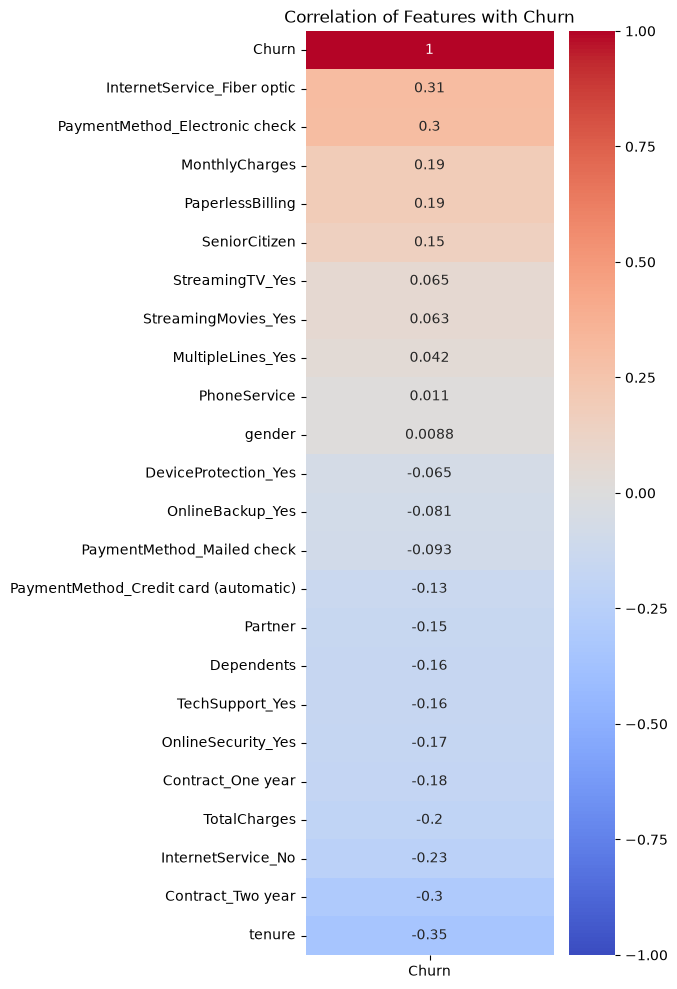

In [72]:
# plot a seaborn heatmap to visualise the relationship between target variable 'Churn' and others
plt.figure(figsize=(4,12))
sns.heatmap(churn_correlation, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation of Features with Churn")
plt.show()

POSITIVE values means more likely to Churn (THREAT)
NEGATIVE values means less likely to chun, most probably stay.

MULTICOLLINEARITY (VIF)

In [73]:
# VIF Check
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Isolate the features by dropping the target variable "Churn"
X = df.drop(columns = ["Churn"])
# # Set up and run VIF
vif_df = pd.DataFrame()
vif_df["Features"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
vif_df = vif_df.sort_values(by = 'VIF', ascending=False)

vif_df


,Features,VIF
7,MonthlyCharges,861.529040
10,InternetService_Fiber optic,147.924238
11,InternetService_No,103.512272
5,PhoneService,34.864993
17,StreamingMovies_Yes,24.072067
16,StreamingTV_Yes,24.019367
8,TotalCharges,10.810003
4,tenure,7.518158
9,MultipleLines_Yes,7.260931
14,DeviceProtection_Yes,6.913552


EDA is done. 
Save the processed file to the processed path.

In [74]:
processed_file_path = DATA_PROCESSED/"Telco-Customer-Churn-Processed.csv"
df.to_csv(processed_file_path, index=False)
print(f"Final processed data is stored in {processed_file_path}")
df.shape

Final processed data is stored in /Users/greeshmagigi/Documents/Project-Telco/data/processed/Telco-Customer-Churn-Processed.csv


(7021, 24)